# 01 - Exploratory Data Analysis

Overview of the Goodreads-10k dataset after filtering (min_user_ratings=5, min_book_ratings=10).

- Rating distribution
- User activity distribution
- Book popularity distribution
- Top tags


In [1]:

import os
import sys
from pathlib import Path

p = Path.cwd()
while p != p.parent and not (p / "configs" / "config.yaml").exists():
    p = p.parent
if (p / "configs" / "config.yaml").exists():
    os.chdir(p)
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("cwd:", Path.cwd())
print("sys.path[0]:", sys.path[0])


cwd: D:\session\recommendSystems\exam\smart_hybrid_bookshelf
sys.path[0]: D:\session\recommendSystems\exam\smart_hybrid_bookshelf


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
Path("reports/figures").mkdir(parents=True, exist_ok=True)

ratings = pd.read_csv("data/raw/ratings.csv")
books = pd.read_csv("data/raw/books.csv")
users = pd.read_csv("data/raw/users.csv")

print("ratings:", ratings.shape)
print("books:", books.shape)
print("users:", users.shape)


ratings: (5976471, 3)
books: (9999, 8)
users: (53424, 1)


In [3]:
n_users = ratings.user_id.nunique()
n_books = ratings.book_id.nunique()
n_ratings = len(ratings)
density = n_ratings / (n_users * n_books)

print("unique users:", n_users)
print("unique books:", n_books)
print("ratings:", n_ratings)
print("density:", round(density, 6))
print("sparsity:", round(1 - density, 6))


unique users: 53424
unique books: 9999
ratings: 5976471
density: 0.011188
sparsity: 0.988812


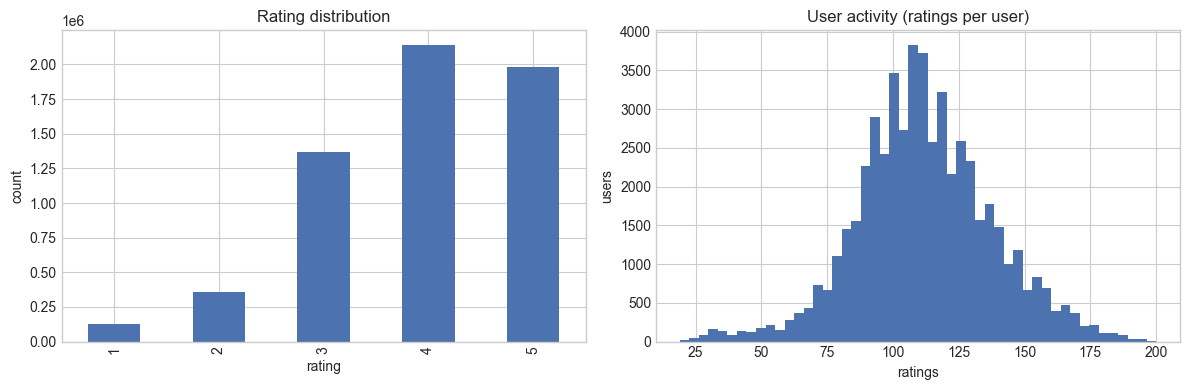

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ratings["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Rating distribution")
axes[0].set_xlabel("rating")
axes[0].set_ylabel("count")

axes[1].hist(ratings.groupby("user_id").size(), bins=50, color="#4C72B0")
axes[1].set_title("User activity (ratings per user)")
axes[1].set_xlabel("ratings")
axes[1].set_ylabel("users")

plt.tight_layout()
plt.savefig("reports/figures/eda_ratings.png", dpi=100)
plt.show()


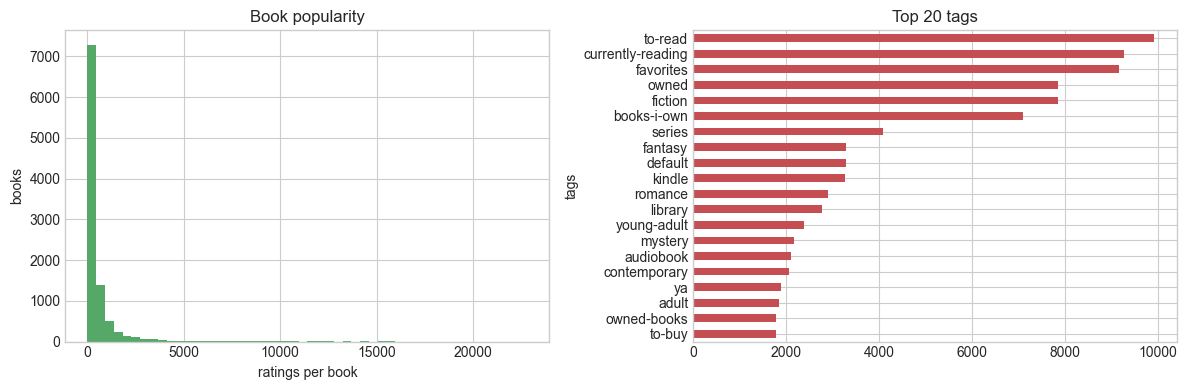

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(ratings.groupby("book_id").size(), bins=50, color="#55A868")
axes[0].set_title("Book popularity")
axes[0].set_xlabel("ratings per book")
axes[0].set_ylabel("books")

tag_counts = books["tags"].str.split("|").explode().value_counts().head(20)
tag_counts.plot(kind="barh", ax=axes[1], color="#C44E52")
axes[1].set_title("Top 20 tags")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig("reports/figures/eda_books_tags.png", dpi=100)
plt.show()


## Key observations

- Dataset is heavily sparse (~1.1% density after filtering)
- Rating distribution is left-skewed (users rate books they like)
- Activity distribution is long-tailed: most users rate few books
- Popularity distribution is also long-tailed: few books dominate
